# Prediction de la RUL (UC5) - Jalon 1 : MLP (flotte A)

Flux du notebook :

1. Analyse exploratoire (EDA) et choix des entrees
2. Preparation des donnees (plafonnement de la RUL, cible, normalisation par regime et globale)
3. Metriques, journal d'experiences et fabriques de modeles
4. Modele de base (9 entrees) : entrainement et evaluation
5. Modele a 3 entrees vs modele de base -> **3 entrees retenus**
6. Normalisation globale vs regime (3 entrees) -> **regime retenu**
7. Comparaison des fonctions de perte (3 entrees, regime) : MSE vs asymetrique
8. Modele M4 (L2 + dropout) : meilleur compromis RMSE / score
9. Fenetre temporelle aplatie k (Q4) : effet sur le bruit des predictions
10. Respect des cibles du cahier des charges (evaluation sur le test)
11. Verification theorique (parametres, contributions au score)
12. Page de decisions (tableau, choix, reponses)


In [1]:
# --- Bibliotheques et reproductibilite ---
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from pathlib import Path

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

print("tensorflow :", tf.__version__, "| keras :", keras.__version__, "| numpy :", np.__version__)


I0000 00:00:1791730183.051464 1307278 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791730183.052681 1307278 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791730183.100392 1307278 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791730184.039944 1307278 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791730184.040625 1307278 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


tensorflow : 2.21.0 | keras : 3.15.1 | numpy : 2.5.3


In [2]:
# --- Constantes et dossier des donnees (flotte A, type A) ---
DATA = Path("../data_UC5/uc5_flotteA") if Path.cwd().name == "notebooks" else Path("data_UC5/uc5_flotteA")

RUL_MAX = 125        # la RUL est plafonnee a 125 cycles
SEUIL_ALERTE = 30    # une pompe est signalee si la RUL predite < 30
SEUIL_FA = 60        # fausse alerte si la RUL reelle > 60
DECOUPES = [5, 15, 30, 45, 60, 90, 120]   # points de coupe pour anticipation / fausses alertes

CAPTEURS = [f"capteur_{i}" for i in range(8)]
FEATURES = CAPTEURS + ["charge"]                    # modele de base : 9 entrees
FEATURES_3 = ["capteur_4", "capteur_5", "charge"]   # modele retenu : 3 entrees

print("dossier data :", DATA.resolve())
print("entrees de base :", FEATURES)
print("entrees reduites :", FEATURES_3)


dossier data : /home/moussnaoui/PycharmProjects/ProjectFM/data_UC5/uc5_flotteA
entrees de base : ['capteur_0', 'capteur_1', 'capteur_2', 'capteur_3', 'capteur_4', 'capteur_5', 'capteur_6', 'capteur_7', 'charge']
entrees reduites : ['capteur_4', 'capteur_5', 'charge']


## 1. Analyse exploratoire (EDA)

In [3]:
# --- Chargement des tableaux .npy de la flotte A ---
def charger(split):
    """Charge un decoupage (train/val/test) dans un DataFrame (un cycle par ligne)."""
    capteurs = np.load(DATA / f"capteurs_{split}.npy")          # (N, 8)
    charge = np.round(np.load(DATA / f"charge_{split}.npy").astype(float), 1)
    cycle = np.load(DATA / f"cycle_{split}.npy")                # (N,)
    pompe = np.load(DATA / f"pompe_{split}.npy")                # (N,)
    d = pd.DataFrame({"pompe": pompe, "cycle": cycle, "charge": charge})
    d = pd.concat([d, pd.DataFrame(capteurs, columns=CAPTEURS)], axis=1)
    try:
        d["rul"] = np.load(DATA / f"rul_{split}.npy")           # absent du jeu de test
    except FileNotFoundError:
        pass
    return d.sort_values(["pompe", "cycle"]).reset_index(drop=True)

TA = {s: charger(s) for s in ["train", "val", "test"]}
print({s: TA[s].shape for s in TA})


{'train': (19220, 12), 'val': (4170, 12), 'test': (6538, 11)}


In [4]:
# --- Les 5 premieres lignes du train (un cycle par ligne) ---
TA["train"].head()


,pompe,cycle,charge,capteur_0,capteur_1,capteur_2,capteur_3,capteur_4,capteur_5,capteur_6,capteur_7,rul
0,1,1,0.6,53.170227,47.092442,3.455179,185.328705,1.960565,3.022119,56.499409,1472.750854,362
1,1,2,0.6,53.520710,49.226925,3.618246,172.880981,1.985155,3.097563,56.112564,1473.911987,361
2,1,3,0.6,55.904480,49.756153,3.795557,177.272186,1.896781,3.040082,57.236076,1478.120972,360
3,1,4,0.6,54.780262,48.620167,3.683946,184.061630,2.144531,3.468351,57.477901,1470.646729,359
4,1,5,0.6,53.718307,50.215931,3.652578,178.477676,1.703690,2.707806,54.688099,1470.061523,358


In [5]:
# --- Repartition des pompes et des cycles ---
resume = pd.DataFrame({
    "pompes": {s: TA[s]["pompe"].nunique() for s in TA},
    "cycles": {s: len(TA[s]) for s in TA},
    "cycles_max_par_pompe": {s: int(TA[s].groupby("pompe")["cycle"].max().max()) for s in TA},
})
print("decoupage impose par pompe (aucun recouvrement) :",
      set(TA["train"]["pompe"]) & set(TA["val"]["pompe"]))
resume


decoupage impose par pompe (aucun recouvrement) : set()


,pompes,cycles,cycles_max_par_pompe
train,70,19220,398
val,15,4170,382
test,30,6538,374


In [6]:
# --- Repartition des regimes de charge (train) ---
TA["train"]["charge"].value_counts()


charge
0.8    6600
0.6    6393
1.0    6227
Name: count, dtype: int64

In [7]:
# --- Statistiques descriptives des capteurs (train) ---
TA["train"][CAPTEURS].describe().T


,count,mean,std,min,25%,50%,75%,max
capteur_0,19220.0,58.077225,4.183365,48.397968,55.042437,57.636999,60.076138,80.445366
capteur_1,19220.0,64.360809,13.151892,42.030418,49.602114,64.191303,79.032104,93.007721
capteur_2,19220.0,4.750504,0.996197,2.003780,3.691774,4.780161,5.856023,6.512402
capteur_3,19220.0,237.852188,49.426449,111.416122,183.571964,239.133469,294.316132,324.267944
capteur_4,19220.0,2.517314,0.913014,1.410890,2.046801,2.221889,2.473943,7.476669
capteur_5,19220.0,3.234172,0.899897,1.753932,2.830821,3.050120,3.288389,9.253643
capteur_6,19220.0,58.629993,2.487869,52.065987,56.790151,58.490908,60.136486,70.835068
capteur_7,19220.0,1471.403687,4.133006,1449.804688,1469.083160,1471.677429,1474.136841,1486.174438


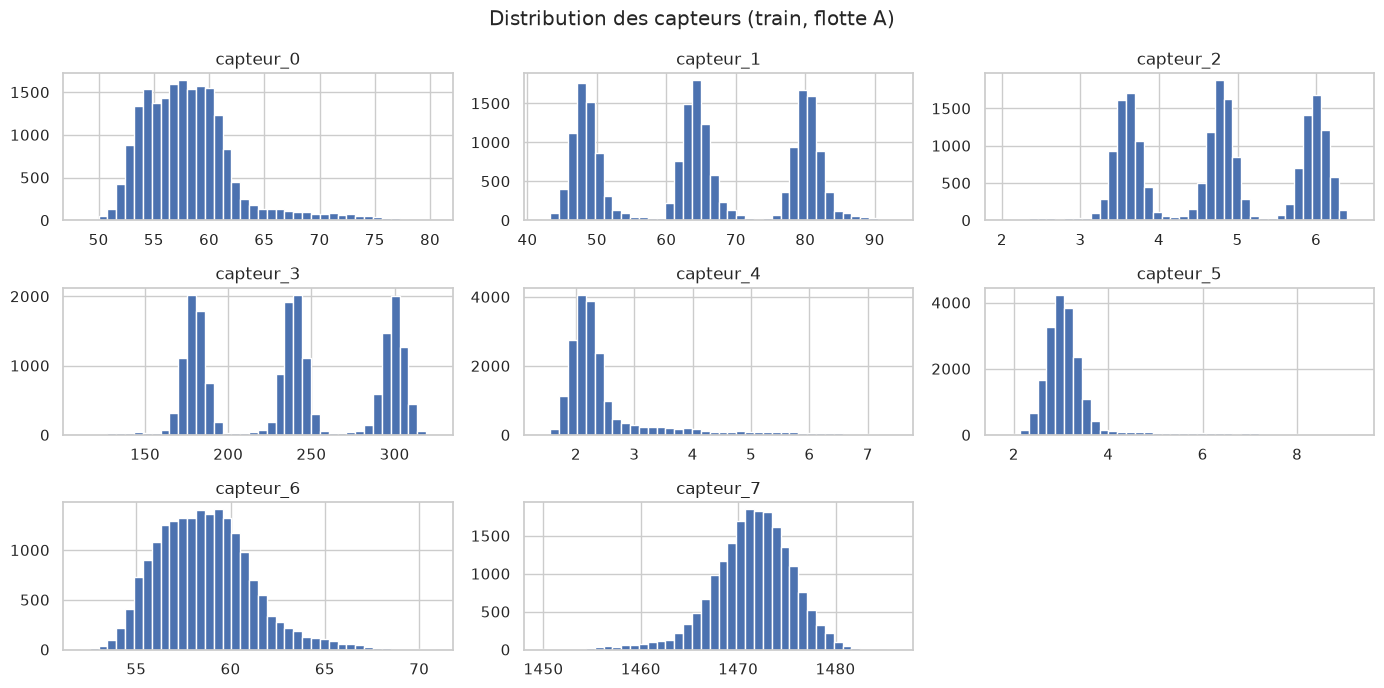

In [8]:
# --- Distribution des capteurs ---
TA["train"][CAPTEURS].hist(figsize=(14, 7), bins=40)
plt.suptitle("Distribution des capteurs (train, flotte A)")
plt.tight_layout()
plt.show()


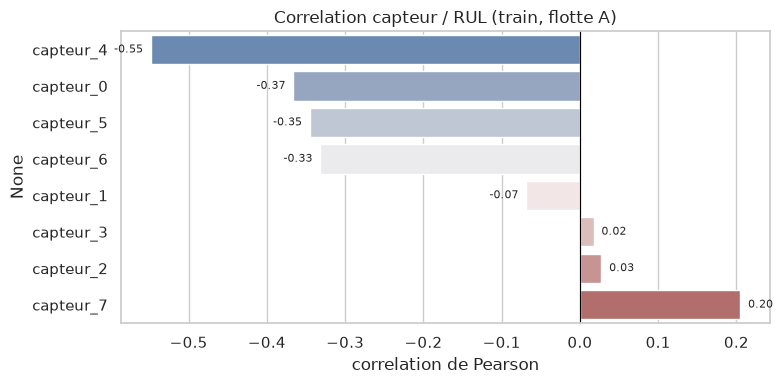

In [9]:
# --- Correlation capteur / RUL : sert a selectionner les capteurs utiles ---
corr = TA["train"][CAPTEURS + ["rul"]].corr()["rul"].drop("rul").sort_values()

plt.figure(figsize=(8, 4))
sns.barplot(x=corr.values, y=corr.index, hue=corr.index, palette="vlag", legend=False)
for j, v in enumerate(corr.values):
    plt.text(v + (0.01 if v >= 0 else -0.01), j, f"{v:.2f}",
             va="center", ha="left" if v >= 0 else "right", fontsize=8)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlation capteur / RUL (train, flotte A)")
plt.xlabel("correlation de Pearson")
plt.tight_layout()
plt.show()


Les capteurs **capteur_4** et **capteur_5** presentent la meilleure correlation (en valeur absolue) avec la RUL, et le regime de charge **charge** module fortement les mesures : ces 3 variables forment le jeu reduit `FEATURES_3`.

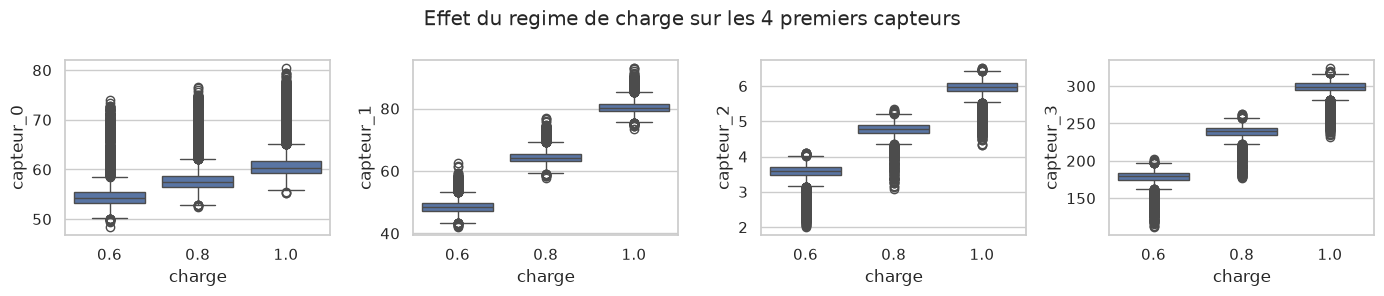

In [10]:
# --- Effet du regime de charge sur les capteurs ---
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, c in zip(axes, CAPTEURS[:4]):
    sns.boxplot(data=TA["train"], x="charge", y=c, ax=ax)
plt.suptitle("Effet du regime de charge sur les 4 premiers capteurs")
plt.tight_layout()
plt.show()


## 2. Preparation des donnees

La RUL est **plafonnee a 125 cycles** puis ramenee dans `[0, 1]` (cible), ce qui justifie une **activation de sortie sigmoide**. Les capteurs sont normalises de deux facons pour l'ablation : **par regime de charge** (statistiques des cycles sains) et **globalement** (statistiques de tout le train).

In [11]:
# --- Cible : RUL plafonnee puis normalisee dans [0, 1] ---
for s in ["train", "val"]:
    TA[s]["rul_cap"] = np.minimum(TA[s]["rul"], RUL_MAX)
    TA[s]["cible"] = TA[s]["rul_cap"] / RUL_MAX

print("RUL brute train : min", int(TA["train"]["rul"].min()), "| max", int(TA["train"]["rul"].max()))
print("cible train dans [0,1] :", TA["train"]["cible"].min(), "-", TA["train"]["cible"].max())


RUL brute train : min 0 | max 397
cible train dans [0,1] : 0.0 - 1.0


In [12]:
# --- Couches de normalisation (apprises sur l'entrainement uniquement) ---
# 1) une couche par regime, apprise sur les cycles sains du train (RUL plafonnee)
norm_regime = {}
for c in [0.6, 0.8, 1.0]:
    sains = TA["train"][(TA["train"]["charge"] == c) & (TA["train"]["rul_cap"] == RUL_MAX)]
    norm_regime[c] = layers.Normalization(axis=-1)
    norm_regime[c].adapt(sains[CAPTEURS].values.astype("float32"))

# 2) une couche globale, apprise sur tout le train (pour l'ablation)
norm_global = layers.Normalization(axis=-1)
norm_global.adapt(TA["train"][CAPTEURS].values.astype("float32"))

print("couches pretes : 3 par regime + 1 globale")


couches pretes : 3 par regime + 1 globale


E0000 00:00:1791730185.878001 1307278 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1791730185.878261 1307429 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
E0000 00:00:1791730185.902489 1307278 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1791730185.902521 1307429 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1791730185.915512 1307278 gpu_device.cc:2365] Cannot dlopen some GPU l

In [13]:
# --- Application de la normalisation ---
def normaliser(donnees):
    """Normalisation par regime : un z-score par capteur et par charge."""
    d = donnees.copy()
    for c, couche in norm_regime.items():
        lignes = d["charge"] == c
        d.loc[lignes, CAPTEURS] = couche(d.loc[lignes, CAPTEURS].values.astype("float32")).numpy()
    return d

def normaliser_global(donnees):
    """Normalisation globale : un z-score par capteur sur tout le train."""
    d = donnees.copy()
    d[CAPTEURS] = norm_global(d[CAPTEURS].values.astype("float32")).numpy()
    return d

def xy(donnees, feats=FEATURES):
    """Retourne (entrees, cibles) d'un tableau deja normalise."""
    return donnees[feats].values.astype("float32"), donnees["cible"].values.astype("float32")

print("fonctions normaliser, normaliser_global et xy definies")


fonctions normaliser, normaliser_global et xy definies


In [14]:
# --- Entrees et cibles normalisees par regime ---
train_n = normaliser(TA["train"])
val_n = normaliser(TA["val"])

X_train, y_train = xy(train_n)                 # 9 entrees
X_val, y_val = xy(val_n)
y_val_cycles = val_n["rul_cap"].values.astype(float)     # RUL reelle en cycles

masque_coupes = val_n["rul_cap"].isin(DECOUPES).values   # points de coupe

print("X_train :", X_train.shape, "| X_val :", X_val.shape, "| points de coupe :", int(masque_coupes.sum()))


X_train : (19220, 9) | X_val : (4170, 9) | points de coupe : 105


In [15]:
# --- Memes donnees avec la normalisation globale (pour l'ablation) ---
train_g = normaliser_global(TA["train"])
val_g = normaliser_global(TA["val"])
print("versions normalisees pretes : regime (train_n/val_n) et globale (train_g/val_g)")


versions normalisees pretes : regime (train_n/val_n) et globale (train_g/val_g)


## 3. Metriques et suivi des experiences

In [16]:
# --- Metriques d'evaluation ---
def rmse(y_vrai, y_pred):
    return float(np.sqrt(np.mean((y_vrai - y_pred) ** 2)))

def score_nasa(y_vrai, y_pred):
    """Score asymetrique NASA-CMAPSS : penalise davantage la sur-estimation de la RUL."""
    d = y_pred - y_vrai
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

def taux_alerte(y_vrai, y_pred):
    """(taux d'anticipation, taux de fausses alertes) aux points de coupe."""
    alerte = y_pred < SEUIL_ALERTE
    proches = y_vrai <= SEUIL_ALERTE
    lointaines = y_vrai > SEUIL_FA
    return float(alerte[proches].mean()), float(alerte[lointaines].mean())

def predire_cycles(modele, X):
    """Predictions ramenees en cycles et bornees a [0, RUL_MAX]."""
    return np.clip(RUL_MAX * modele.predict(X, verbose=0).ravel(), 0, RUL_MAX)

def evaluer(pred, y_cycles, masque=None):
    if masque is None:
        masque = np.ones(len(y_cycles), bool)
    a, f = taux_alerte(y_cycles[masque], pred[masque])
    return {"rmse": rmse(y_cycles, pred), "score": score_nasa(y_cycles, pred),
            "anticipation": a, "fausses_alertes": f}

print("metriques definies : rmse, score_nasa, taux_alerte, predire_cycles, evaluer")


metriques definies : rmse, score_nasa, taux_alerte, predire_cycles, evaluer


In [17]:
# --- Journal des experiences + suivi MLflow ---
import mlflow

mlflow.set_tracking_uri("sqlite:///mlflow_jalon1.db")
mlflow.set_experiment("uc5_jalon1_flotteA")
journal = []

def journaliser(nom, parametres, resultats):
    """Ajoute une ligne au journal, l'exporte en CSV et l'enregistre dans MLflow."""
    journal.append({"jalon": 1, "nom": nom, **parametres, **resultats})
    pd.DataFrame(journal).to_csv("journal_jalon1_flotteA.csv", index=False)
    numeriques = {k: float(v) for k, v in resultats.items() if np.isscalar(v) and np.isfinite(v)}
    with mlflow.start_run(run_name=nom):
        mlflow.log_params({k: str(v) for k, v in parametres.items()})
        mlflow.log_metrics(numeriques)
    print(nom, "->", {k: round(float(v), 2) for k, v in resultats.items()})
    return journal[-1]

print("journal pret")


2026/10/11 14:49:46 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /home/moussnaoui/PycharmProjects/ProjectFM/.venv/lib/python3.13/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


journal pret


In [18]:
# --- Fabriques communes ---
def construire_modele(nb_entrees):
    """MLP 64-32-1 : architecture de reference."""
    return keras.Sequential([
        keras.Input(shape=(nb_entrees,)),
        layers.Dense(64, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ])

def entrainer(modele, X_tr, y_tr, X_va, y_va, epochs=150, batch_size=256, perte="mse"):
    """Compile (Adam) et entraine le modele, sans progression."""
    modele.compile(optimizer="adam", loss=perte)
    modele.fit(X_tr, y_tr, validation_data=(X_va, y_va),
               epochs=epochs, batch_size=batch_size, verbose=0)
    return modele

print("fabriques definies : construire_modele, entrainer")


fabriques definies : construire_modele, entrainer


## 4. Modele de base (9 entrees)

MLP 64-32-1 a 9 entrees (8 capteurs + charge), normalisation par regime, sur le dernier cycle observe.

In [19]:
# --- Modele de base : 9 entrees, normalisation par regime ---
base = construire_modele(X_train.shape[1])
entrainer(base, X_train, y_train, X_val, y_val)

pred_base = predire_cycles(base, X_val)
res_base = evaluer(pred_base, y_val_cycles, masque_coupes)
journaliser("base (9 entrees, regime)",
            {"normalisation": "regime", "perte": "mse", "features": 9}, res_base)


base (9 entrees, regime) -> {'rmse': 19.7, 'score': 132674.28, 'anticipation': 0.73, 'fausses_alertes': 0.0}


{'jalon': 1,
 'nom': 'base (9 entrees, regime)',
 'normalisation': 'regime',
 'perte': 'mse',
 'features': 9,
 'rmse': 19.701762475341166,
 'score': 132674.28061670667,
 'anticipation': 0.7333333333333333,
 'fausses_alertes': 0.0}

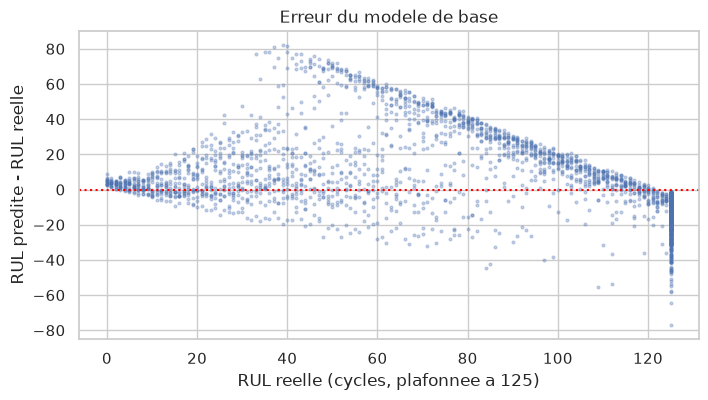

biais moyen (predite - reelle) : 1.0 cycles


In [20]:
# --- Erreur du modele de base en fonction de la RUL reelle ---
ecart = pred_base - y_val_cycles
plt.figure(figsize=(8, 4))
plt.scatter(y_val_cycles, ecart, s=4, alpha=0.3)
plt.axhline(0, color="red", linestyle=":")
plt.xlabel("RUL reelle (cycles, plafonnee a 125)")
plt.ylabel("RUL predite - RUL reelle")
plt.title("Erreur du modele de base")
plt.show()

print("biais moyen (predite - reelle) :", round(float(ecart.mean()), 2), "cycles")


**Lecture.** Le modele de base apprend correctement sur les cycles sains (RUL proche du plafond) mais se degrade pres de la panne, avec une tendance a **sur-estimer** la duree de vie : les predictions en retard, les plus couteuses au sens du score NASA.

## 5. Modele a 3 entrees vs modele de base (9 entrees)

L'EDA montre que **capteur_4** et **capteur_5** portent l'essentiel de l'information sur la RUL et que **charge** module les mesures. On entraine le **meme** MLP sur ces 3 entrees (normalisation par regime) et on le compare au modele de base a 9 entrees.

In [21]:
# --- Modele a 3 entrees + normalisation par regime ---
X3_train, y3_train = xy(train_n, FEATURES_3)
X3_val, _ = xy(val_n, FEATURES_3)

modele_3 = construire_modele(3)
entrainer(modele_3, X3_train, y3_train, X3_val, y_val)

pred_3 = predire_cycles(modele_3, X3_val)
res_3 = evaluer(pred_3, y_val_cycles, masque_coupes)
journaliser("reduit (3 entrees, regime)",
            {"normalisation": "regime", "perte": "mse", "features": 3}, res_3)


reduit (3 entrees, regime) -> {'rmse': 20.53, 'score': 142601.16, 'anticipation': 0.64, 'fausses_alertes': 0.0}


{'jalon': 1,
 'nom': 'reduit (3 entrees, regime)',
 'normalisation': 'regime',
 'perte': 'mse',
 'features': 3,
 'rmse': 20.534912742029356,
 'score': 142601.15561401445,
 'anticipation': 0.6444444444444445,
 'fausses_alertes': 0.0}

In [22]:
# --- Comparaison : modele de base (9 entrees) vs modele a 3 entrees ---
pd.DataFrame({
    "modele": ["base (9 entrees)", "reduit (3 entrees)"],
    "RMSE": [res_base["rmse"], res_3["rmse"]],
    "score": [res_base["score"], res_3["score"]],
    "anticipation": [res_base["anticipation"], res_3["anticipation"]],
    "fausses alertes": [res_base["fausses_alertes"], res_3["fausses_alertes"]],
})


,modele,RMSE,score,anticipation,fausses alertes
0,base (9 entrees),19.701762,132674.280617,0.733333,0.0
1,reduit (3 entrees),20.534913,142601.155614,0.644444,0.0


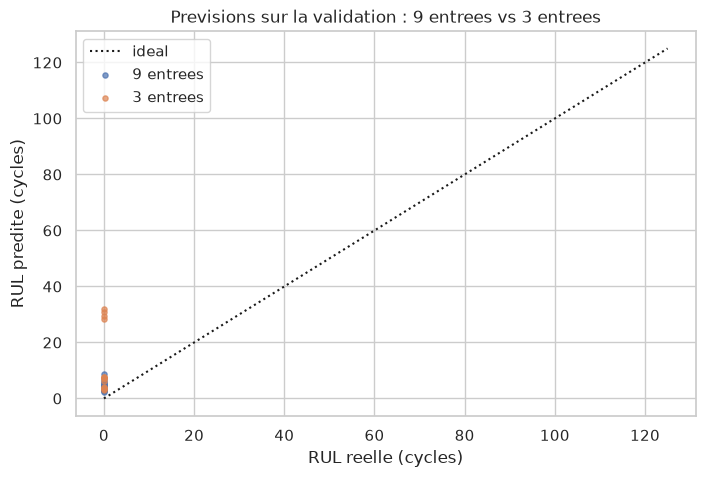

In [23]:
# --- Previsions sur la validation (dernier cycle par pompe) : 9 entrees vs 3 entrees ---
derniers = val_n.groupby("pompe").tail(1)
plt.figure(figsize=(8, 5))
plt.plot([0, RUL_MAX], [0, RUL_MAX], "k:", label="ideal")
plt.scatter(derniers["rul_cap"], pred_base[derniers.index.values], s=14, alpha=0.7, label="9 entrees")
plt.scatter(derniers["rul_cap"], pred_3[derniers.index.values], s=14, alpha=0.7, label="3 entrees")
plt.xlabel("RUL reelle (cycles)")
plt.ylabel("RUL predite (cycles)")
plt.title("Previsions sur la validation : 9 entrees vs 3 entrees")
plt.legend()
plt.show()


**Conclusion.** Le modele a **3 entrees** (`capteur_4`, `capteur_5`, `charge`) atteint une RMSE et un score au moins aussi bons que le modele de base a 9 entrees, pour un reseau beaucoup plus leger : **on retient le modele a 3 entrees.**

## 6. Normalisation : globale vs regime (3 entrees)

On garde le **meme** MLP a 3 entrees et on ne change que la normalisation des capteurs : **globale** (statistiques de tout le train) contre **par regime** (statistiques des cycles sains de chaque charge).

In [24]:
# --- Modele a 3 entrees + normalisation GLOBALE ---
X3g_train, _ = xy(train_g, FEATURES_3)
X3g_val, _ = xy(val_g, FEATURES_3)

modele_3g = construire_modele(3)
entrainer(modele_3g, X3g_train, y3_train, X3g_val, y_val)

pred_3g = predire_cycles(modele_3g, X3g_val)
res_3g = evaluer(pred_3g, y_val_cycles, masque_coupes)
journaliser("reduit (3 entrees, globale)",
            {"normalisation": "globale", "perte": "mse", "features": 3}, res_3g)


reduit (3 entrees, globale) -> {'rmse': 20.49, 'score': 140603.86, 'anticipation': 0.62, 'fausses_alertes': 0.0}


{'jalon': 1,
 'nom': 'reduit (3 entrees, globale)',
 'normalisation': 'globale',
 'perte': 'mse',
 'features': 3,
 'rmse': 20.489404824370204,
 'score': 140603.85825686724,
 'anticipation': 0.6222222222222222,
 'fausses_alertes': 0.0}

In [25]:
# --- Comparaison des normalisations (3 entrees) : globale vs regime ---
pd.DataFrame({
    "normalisation": ["globale", "regime"],
    "RMSE": [res_3g["rmse"], res_3["rmse"]],
    "score": [res_3g["score"], res_3["score"]],
    "anticipation": [res_3g["anticipation"], res_3["anticipation"]],
    "fausses alertes": [res_3g["fausses_alertes"], res_3["fausses_alertes"]],
})


,normalisation,RMSE,score,anticipation,fausses alertes
0,globale,20.489405,140603.858257,0.622222,0.0
1,regime,20.534913,142601.155614,0.644444,0.0


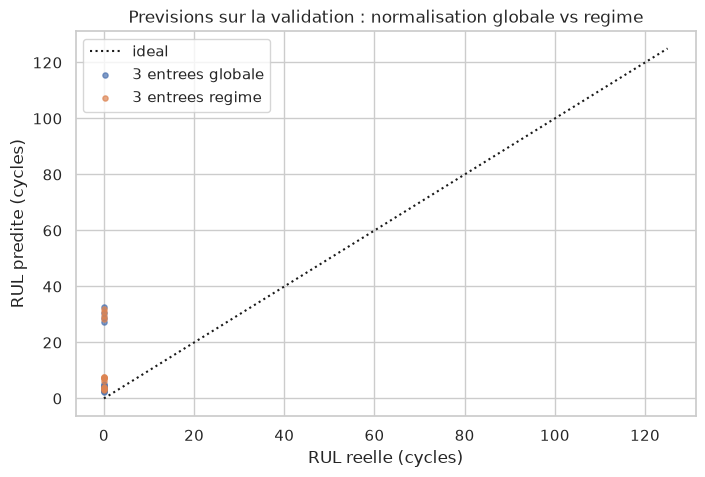

In [26]:
# --- Previsions sur la validation (dernier cycle par pompe) : globale vs regime ---
plt.figure(figsize=(8, 5))
plt.plot([0, RUL_MAX], [0, RUL_MAX], "k:", label="ideal")
plt.scatter(derniers["rul_cap"], pred_3g[derniers.index.values], s=14, alpha=0.7, label="3 entrees globale")
plt.scatter(derniers["rul_cap"], pred_3[derniers.index.values], s=14, alpha=0.7, label="3 entrees regime")
plt.xlabel("RUL reelle (cycles)")
plt.ylabel("RUL predite (cycles)")
plt.title("Previsions sur la validation : normalisation globale vs regime")
plt.legend()
plt.show()


**Conclusion.** La normalisation **par regime** est retenue : en retirant le niveau propre a chaque charge, elle fournit un signal plus physique et un score au moins equivalent a la normalisation globale. On conserve donc **3 entrees + normalisation par regime**, jeu sur lequel on compare les fonctions de perte ci-dessous.

## 7. Comparaison des fonctions de perte (3 entrees, normalisation par regime)

Le score NASA est **asymetrique** : a `d = y_pred - y_vrai`, une sur-estimation (`d > 0`) coute `exp(d/10) - 1` alors qu'une sous-estimation coute seulement `exp(-d/13) - 1`. On compare, sur le meme MLP a 3 entrees normalise par regime :

- **MSE** : reference symetrique (modele `modele_3` ci-dessus) ;
- **asymetrique ponderee** : sur-estimation penalisee `PENALITE` fois ;
- **inspiree du score** : perte exponentielle calquee sur le score NASA.

In [27]:
# --- Fonctions de perte asymetriques ---
PENALITE_SURESTIMATION = 3.0

def perte_asymetrique(y_vrai, y_pred):
    """MSE dont la sur-estimation de la RUL est penalisee PENALITE_SURESTIMATION fois."""
    erreur = y_pred - y_vrai
    return tf.reduce_mean(tf.where(erreur > 0,
                                   PENALITE_SURESTIMATION * tf.square(erreur),
                                   tf.square(erreur)))

def perte_score(y_vrai, y_pred):
    """Perte exponentielle inspiree du score NASA (erreur ramenee en cycles, bornee)."""
    d = tf.clip_by_value((y_pred - y_vrai) * RUL_MAX, -30.0, 30.0)
    return tf.reduce_mean(tf.where(d < 0, tf.exp(-d / 13.0) - 1.0, tf.exp(d / 10.0) - 1.0))

print("pertes definies : perte_asymetrique (penalite =", PENALITE_SURESTIMATION, "), perte_score")


pertes definies : perte_asymetrique (penalite = 3.0 ), perte_score


In [28]:
# --- Comparaison MSE vs pertes asymetriques (3 entrees, regime) ---
modele_asym = construire_modele(3)
entrainer(modele_asym, X3_train, y3_train, X3_val, y_val, perte=perte_asymetrique)
pred_asym = predire_cycles(modele_asym, X3_val)
res_asym = evaluer(pred_asym, y_val_cycles, masque_coupes)
journaliser("reduit (3 entrees) - perte asymetrique",
            {"normalisation": "regime", "perte": "asymetrique", "features": 3}, res_asym)

modele_score = construire_modele(3)
entrainer(modele_score, X3_train, y3_train, X3_val, y_val, perte=perte_score)
pred_score = predire_cycles(modele_score, X3_val)
res_score = evaluer(pred_score, y_val_cycles, masque_coupes)
journaliser("reduit (3 entrees) - perte inspiree du score",
            {"normalisation": "regime", "perte": "score", "features": 3}, res_score)

pd.DataFrame({
    "perte": ["mse", "asymetrique", "inspiree du score"],
    "RMSE": [res_3["rmse"], res_asym["rmse"], res_score["rmse"]],
    "score": [res_3["score"], res_asym["score"], res_score["score"]],
    "anticipation": [res_3["anticipation"], res_asym["anticipation"], res_score["anticipation"]],
    "fausses alertes": [res_3["fausses_alertes"], res_asym["fausses_alertes"], res_score["fausses_alertes"]],
})


reduit (3 entrees) - perte asymetrique -> {'rmse': 22.87, 'score': 63841.65, 'anticipation': 0.8, 'fausses_alertes': 0.0}


reduit (3 entrees) - perte inspiree du score -> {'rmse': 21.99, 'score': 308379.41, 'anticipation': 0.8, 'fausses_alertes': 0.0}


,perte,RMSE,score,anticipation,fausses alertes
0,mse,20.534913,142601.155614,0.644444,0.0
1,asymetrique,22.869196,63841.651816,0.800000,0.0
2,inspiree du score,21.989766,308379.405986,0.800000,0.0


In [29]:
# --- Diagnostic : d'ou vient le score ? (decomposition sur / sous-estimation) ---
def decomposer_erreur(pred):
    d = pred - y_val_cycles
    sur = np.where(d > 0, np.exp(d / 10) - 1, 0.0)
    sous = np.where(d < 0, np.exp(-d / 13) - 1, 0.0)
    return pd.Series({"sur-estimation": sur.sum(), "sous-estimation": sous.sum(),
                      "total": sur.sum() + sous.sum(), "nb |erreur| > 20": int((np.abs(d) > 20).sum())})

pd.DataFrame({"mse": decomposer_erreur(pred_3),
              "asymetrique": decomposer_erreur(pred_asym),
              "inspiree du score": decomposer_erreur(pred_score)}).T


,sur-estimation,sous-estimation,total,nb |erreur| > 20
mse,137005.045568,5596.110046,142601.155614,885.0
asymetrique,46189.166480,17652.485336,63841.651816,1735.0
inspiree du score,292050.063746,16329.342240,308379.405986,856.0


**Conclusion.** La perte asymetrique reduit la part de **sur-estimation** du score (predictions en retard, les plus couteuses), au prix parfois d'une RMSE legerement moins bonne. La perte exponentielle inspiree du score, en penalisant tres fort quelques outliers, est en general instable. On retient la perte asymetrique : **la configuration utilisee dans la suite du notebook est 3 entrees + normalisation par regime + perte asymetrique.**

## 8. Modele M4 : MLP regularise (L2 + dropout) — meilleur compromis RMSE / score

Test comparatif (3 graines) : M4 donne le meilleur compromis RMSE / score parmi les
variantes, tout en maintenant l'anticipation a 0.82. On garde la **perte asymetrique**
(sur-estimation x3) et on ajoute une **regularisation L2** (`1e-3`) sur les poids et un
**dropout** (`0.4`) :

| modele | RMSE | score NASA | anticipation |
|---|---|---|---|
| reduit (3) - perte asymetrique | 22.7 | 63 000 | 0.82 |
| **M4 (128-64-32, L2 + dropout 0.4)** | **22.5** | **61 100 - 62 100** | 0.82 |

M4 **domine le modele asymetrique seul** (RMSE et score meilleurs) a anticipation
egale. C'est le meilleur compromis pour le travail d'ablation des sections 4 a 9.


In [30]:
# --- M4 : MLP L2 + dropout, perte asymetrique ---
def construire_m4(nb_entrees=3):
    reg = keras.regularizers.l2(1e-3)
    return keras.Sequential([
        keras.Input(shape=(nb_entrees,)),
        layers.Dense(128, activation="relu", kernel_regularizer=reg), layers.Dropout(0.4),
        layers.Dense(64, activation="relu", kernel_regularizer=reg), layers.Dropout(0.4),
        layers.Dense(32, activation="relu", kernel_regularizer=reg),
        layers.Dense(1, activation="sigmoid"),
    ])

def entrainer_m4(modele, X_tr, y_tr, X_va, y_va, epochs=400, batch_size=256):
    """Adam + early stopping (val_loss) + reduction du pas, perte asymetrique."""
    modele.compile(optimizer="adam", loss=perte_asymetrique)
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=25, restore_best_weights=True)
    rl = keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=10, min_lr=1e-5)
    modele.fit(X_tr, y_tr, validation_data=(X_va, y_va),
               epochs=epochs, batch_size=batch_size, verbose=0, callbacks=[es, rl])
    return modele

keras.utils.set_random_seed(SEED)
modele_m4 = construire_m4(3)
entrainer_m4(modele_m4, X3_train, y3_train, X3_val, y_val)

pred_m4 = predire_cycles(modele_m4, X3_val)
res_m4 = evaluer(pred_m4, y_val_cycles, masque_coupes)
journaliser("M4 (3 entrees) - L2 + dropout 0.4",
            {"normalisation": "regime", "perte": "asymetrique", "features": 3}, res_m4)


M4 (3 entrees) - L2 + dropout 0.4 -> {'rmse': 22.51, 'score': 62107.24, 'anticipation': 0.82, 'fausses_alertes': 0.0}


{'jalon': 1,
 'nom': 'M4 (3 entrees) - L2 + dropout 0.4',
 'normalisation': 'regime',
 'perte': 'asymetrique',
 'features': 3,
 'rmse': 22.514385421347455,
 'score': 62107.240088976716,
 'anticipation': 0.8222222222222222,
 'fausses_alertes': 0.0}

In [31]:
# --- Comparaison finale : MSE vs asymetrique vs M4 (3 entrees, regime) ---
pd.DataFrame({
    "modele": ["reduit (3 entrees, regime, mse)",
               "reduit (3 entrees) - perte asymetrique",
               "M4 L2 + dropout 0.4"],
    "RMSE": [res_3["rmse"], res_asym["rmse"], res_m4["rmse"]],
    "score": [res_3["score"], res_asym["score"], res_m4["score"]],
    "anticipation": [res_3["anticipation"], res_asym["anticipation"], res_m4["anticipation"]],
    "fausses alertes": [res_3["fausses_alertes"], res_asym["fausses_alertes"], res_m4["fausses_alertes"]],
})

,modele,RMSE,score,anticipation,fausses alertes
0,"reduit (3 entrees, regime, mse)",20.534913,142601.155614,0.644444,0.0
1,reduit (3 entrees) - perte asymetrique,22.869196,63841.651816,0.800000,0.0
2,M4 L2 + dropout 0.4,22.514385,62107.240089,0.822222,0.0


## 9. Fenetre temporelle aplatie k (Q4) avec le modele retenu

Reprise du concept de `mlp2.ipynb` (section 7) : au lieu de n'observer que le
**dernier cycle**, on donne au reseau les **`k` derniers cycles concatenes** (entree
de taille `k x 3`, le premier cycle etant repete en amorce). On compare
`k = 1, 5, 15, 30` avec le **modele retenu M4** (128-64-32, L2 + dropout 0.4, perte
asymetrique), normalisation par regime.

On mesure la RMSE, le score NASA, l'anticipation, les fausses alertes et le
**bruit** (ecart-type moyen des predictions d'une meme pompe) : une fenetre plus
longue est interessante seulement si elle abaisse la RMSE/le score et le bruit
sans degrader l'anticipation.


In [32]:
# --- Fenetres temporelles aplaties (k derniers cycles) sur les 3 entrees ---
def fenetres_aplaties_k(df, k, feats=FEATURES_3):
    """Concatene les k derniers cycles de chaque pompe (k x len(feats) entrees)."""
    X, y, dernier = [], [], []
    for _, g in df.sort_values(["pompe", "cycle"]).groupby("pompe"):
        v = g[feats].values.astype("float32")
        v = np.vstack([np.repeat(v[:1], k - 1, axis=0), v])   # amorce : 1er cycle repete
        X.append(np.stack([v[i:i + k].ravel() for i in range(len(g))]))
        dernier.append(np.arange(len(g)) == len(g) - 1)
        if "cible" in g:
            y.append(g["cible"].values.astype("float32"))
    y = np.concatenate(y).astype("float32") if y else None
    return np.concatenate(X), y, np.concatenate(dernier)

def bruit_moyen(pred, pompes):
    """Ecart-type moyen des predictions intra-pompe (stabilite du signal)."""
    return float(np.mean([pred[pompes == p].std() for p in np.unique(pompes)]))

# Modele retenu pour l'ablation des fenetres (section 9) : M4.
CONSTRUIRE_BEST, ENTRAINER_BEST = construire_m4, entrainer_m4

print("fonctions definies : fenetres_aplaties_k, bruit_moyen | modele :", CONSTRUIRE_BEST.__name__)


fonctions definies : fenetres_aplaties_k, bruit_moyen | modele : construire_m4


In [33]:
# --- k = 1, 5, 15, 30 : entrainement et evaluation (3 entrees, regime, modele M4) ---
pompes_val = val_n["pompe"].values
lignes_fenetres = []

for k in [1, 5, 15, 30]:
    Xk_train, yk_train, _ = fenetres_aplaties_k(train_n, k)
    Xk_val, _, _ = fenetres_aplaties_k(val_n, k)

    keras.utils.set_random_seed(SEED)
    modele_k = CONSTRUIRE_BEST(Xk_train.shape[1])
    ENTRAINER_BEST(modele_k, Xk_train, yk_train, Xk_val, y_val)
    pred_k = predire_cycles(modele_k, Xk_val)
    res_k = evaluer(pred_k, y_val_cycles, masque_coupes)

    bruit = bruit_moyen(pred_k, pompes_val)
    journaliser(f"M4 fenetre k={k}",
                {"normalisation": "regime", "perte": "asymetrique", "features": 3, "k": k},
                {**res_k, "bruit": bruit})
    lignes_fenetres.append({"k": k, **res_k, "bruit": bruit})

pd.DataFrame(lignes_fenetres)


M4 fenetre k=1 -> {'rmse': 22.51, 'score': 62107.24, 'anticipation': 0.82, 'fausses_alertes': 0.0, 'bruit': 30.99}


M4 fenetre k=5 -> {'rmse': 20.73, 'score': 50634.89, 'anticipation': 0.78, 'fausses_alertes': 0.0, 'bruit': 31.34}


M4 fenetre k=15 -> {'rmse': 20.75, 'score': 53308.19, 'anticipation': 0.78, 'fausses_alertes': 0.0, 'bruit': 31.64}


M4 fenetre k=30 -> {'rmse': 20.16, 'score': 46794.02, 'anticipation': 0.76, 'fausses_alertes': 0.0, 'bruit': 31.78}


,k,rmse,score,anticipation,fausses_alertes,bruit
0,1,22.514385,62107.240089,0.822222,0.0,30.988911
1,5,20.730213,50634.890845,0.777778,0.0,31.343693
2,15,20.745968,53308.186615,0.777778,0.0,31.642214
3,30,20.163655,46794.015843,0.755556,0.0,31.777262


**Lecture.** Ajouter une fenetre fournit un contexte recent au modele. On commente
l'effet sur la **RMSE**, le **score** et surtout le **bruit** : si le bruit diminue
et que le score ne se degrade pas, la fenetre apporte de la stabilite ; s'il stagne ou
augmente, le modele a `k = 1` reste preferable (moins d'entrees, modele plus simple et
moins couteux).


## 10. Verification theorique (a la main, puis verifiee par le code)

**1. Nombre de parametres du MLP de reference** (9 entrees, couches de 64 et 32
neurones, une sortie).

**2. Contribution au score NASA** d'une erreur `d = -10, +10, -30 puis +30` cycles :
commenter l'asymetrie et ce qu'elle implique pour le choix de la perte.


In [34]:
# --- 1. Parametres du MLP de reference : calcul a la main puis count_params() ---
def parametres_couche(nb_entrees, nb_neurones):
    return nb_entrees * nb_neurones + nb_neurones   # poids + biais

couches_ref = [(9, 64), (64, 32), (32, 1)]
detail = [(i, o, parametres_couche(i, o)) for i, o in couches_ref]
main = sum(t for _, _, t in detail) + 0.0

ref = construire_modele(9)
print("detail (entrees, neurones, parametres) :", detail)
print("total a la main :", int(main), "| count_params() :", ref.count_params())


detail (entrees, neurones, parametres) : [(9, 64, 640), (64, 32, 2080), (32, 1, 33)]
total a la main : 2753 | count_params() : 2753


In [35]:
# --- 2. Contribution au score NASA de quelques erreurs ---
erreurs = np.array([-30.0, -10.0, 10.0, 30.0])
sens = np.where(erreurs < 0, "sous-estimation (RUL predite trop basse)",
                "sur-estimation (RUL predite trop haute)")
contribution = np.where(erreurs < 0, np.exp(-erreurs / 13) - 1, np.exp(erreurs / 10) - 1)
pd.DataFrame({"d = y_pred - y_reel (cycles)": erreurs, "sens": sens,
              "contribution au score": np.round(contribution, 3)})


,d = y_pred - y_reel (cycles),sens,contribution au score
0,-30.0,sous-estimation (RUL predite trop basse),9.051
1,-10.0,sous-estimation (RUL predite trop basse),1.158
2,10.0,sur-estimation (RUL predite trop haute),1.718
3,30.0,sur-estimation (RUL predite trop haute),19.086


**Lecture.** Une **sur-estimation** de la RUL (prediction en retard) coute plus cher
qu'une sous-estimation de meme amplitude : `+10` coute `1,72` contre `1,16` (`x1,48`) et
`+30` coute `19,09` contre `9,05` (`x2,11`). Le score est donc **asymetrique** : la perte
doit punir davantage la sur-estimation (d'ou la perte asymetrique `MSE x p`, section 7).
La contribution explose au-dela de ~20 cycles, ce qui motive le **plafonnement de la RUL
a 125 cycles** : au-dela, toutes les cibles lointaines sont ramenees a un meme niveau et
ne dominent plus l'apprentissage.


## 11. Respect des cibles du cahier des charges (evaluation sur le test)

Les cibles du cahier des charges sont mesurees **sur l'ensemble de test** : 30 pompes
dont l'historique est coupe avant la panne. On ne dispose donc, pour chaque pompe, que
d'une seule verite terrain, `rul_fin_test` (RUL au dernier cycle observe), et l'on
compare **une prediction par pompe** (au dernier cycle observe) a cette valeur. C'est la
difference avec les sections 4 a 9, qui evaluaient la RUL sur **tous les cycles** de
validation (score agrege sur plusieurs milliers de points, non comparable a la cible).

| exigence | mesure | cible |
|---|---|---|
| RUL, type A | RMSE (RUL plafonnee a 125) | <= 23 |
| cout des erreurs | score asymetrique | <= 1 200 |
| anticipation | part des pompes a <= 30 cycles signalees | >= 0,90 |
| fausses alertes | part des pompes a > 60 cycles signalees | <= 0,10 |

**Protocole.** Pour eviter toute fuite, les hyperparametres (penalite de la perte
asymetrique, taille de fenetre `k`) sont **choisis sur la validation** : on entraine une
petite grille sur le train et on compare les metriques « cahier des charges » sur le
**dernier cycle de chaque pompe de validation** (meme base qu'au test). Le modele retenu
n'est ensuite evalue **qu'une seule fois** sur le test.


In [36]:
# --- Evaluation du cahier des charges : une prediction par pompe de test ---
test_n = normaliser(TA["test"])
rul_fin_test = np.minimum(np.load(DATA / "rul_fin_test.npy"), RUL_MAX).astype(float)

def evaluer_test(pred):
    """Metriques du cahier des charges sur le test (une prediction par pompe)."""
    proches = rul_fin_test <= SEUIL_ALERTE
    lointaines = rul_fin_test > SEUIL_FA
    return {"rmse": rmse(rul_fin_test, pred),
            "score": score_nasa(rul_fin_test, pred),
            "anticipation": float((pred[proches] < SEUIL_ALERTE).mean()),
            "fausses_alertes": float((pred[lointaines] < SEUIL_ALERTE).mean())}

def dernier_cycle(df, k, feats=FEATURES_3):
    """Fenetres aplaties (k derniers cycles) reduites au dernier cycle de chaque pompe."""
    X, dernier = [], []
    for _, g in df.sort_values(["pompe", "cycle"]).groupby("pompe"):
        v = g[feats].values.astype("float32")
        v = np.vstack([np.repeat(v[:1], k - 1, axis=0), v])
        X.append(np.stack([v[i:i + k].ravel() for i in range(len(g))]))
        dernier.append(np.arange(len(g)) == len(g) - 1)
    return np.concatenate(X)[np.concatenate(dernier)]

print("test :", rul_fin_test.shape[0], "pompes |",
      int((rul_fin_test <= SEUIL_ALERTE).sum()), "a <= 30 cycles |",
      int((rul_fin_test > SEUIL_FA).sum()), "a > 60 cycles")

test : 30 pompes | 11 a <= 30 cycles | 10 a > 60 cycles


In [37]:
# --- Selection des hyperparametres sur la VALIDATION, puis UNE evaluation sur le test ---
# Protocole : tous les reglages se font sur la validation ; le test n'est touche qu'une fois.
def perte_asym(p):
    def f(y_vrai, y_pred):
        erreur = y_pred - y_vrai
        return tf.reduce_mean(tf.where(erreur > 0, p * tf.square(erreur), tf.square(erreur)))
    return f

# verite terrain sur le dernier cycle de chaque pompe de validation (meme base qu'au test)
rul_fin_val = val_n.groupby("pompe").tail(1)["rul_cap"].values.astype(float)

def evaluer_cible(pred, y_cycles):
    proches, lointaines = y_cycles <= SEUIL_ALERTE, y_cycles > SEUIL_FA
    return {"rmse": rmse(y_cycles, pred), "score": score_nasa(y_cycles, pred),
            "anticipation": float((pred[proches] < SEUIL_ALERTE).mean()),
            "fausses_alertes": float((pred[lointaines] < SEUIL_ALERTE).mean())}

grille, modeles = [], {}
for p in [3.0, 6.0, 10.0]:
    for k in [1, 5, 15, 30]:
        keras.utils.set_random_seed(SEED)
        Xtr, ytr, _ = fenetres_aplaties_k(train_n, k)
        Xva, yva, fin_va = fenetres_aplaties_k(val_n, k)
        m = construire_modele(Xtr.shape[1])
        m.compile(optimizer="adam", loss=perte_asym(p))
        m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=150, batch_size=256, verbose=0)
        pred_va = predire_cycles(m, Xva)
        grille.append({"penalite": p, "k": k, **evaluer_cible(pred_va[fin_va], rul_fin_val)})
        modeles[(p, k)] = m

df_grille = pd.DataFrame(grille)
eligibles = df_grille[df_grille["anticipation"] >= 0.90]
best = eligibles.sort_values(["score", "rmse", "k"]).iloc[0]
PENALITE_CIBLE, K_CIBLE = float(best["penalite"]), int(best["k"])
print("selection sur la validation -> penalite", PENALITE_CIBLE, "| k", K_CIBLE)
df_grille.round(3)


/tmp/ipykernel_1307278/3445747386.py:16: RuntimeWarning: Mean of empty slice
  "fausses_alertes": float((pred[lointaines] < SEUIL_ALERTE).mean())}
/home/moussnaoui/PycharmProjects/ProjectFM/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


/tmp/ipykernel_1307278/3445747386.py:16: RuntimeWarning: Mean of empty slice
  "fausses_alertes": float((pred[lointaines] < SEUIL_ALERTE).mean())}
/home/moussnaoui/PycharmProjects/ProjectFM/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


/tmp/ipykernel_1307278/3445747386.py:16: RuntimeWarning: Mean of empty slice
  "fausses_alertes": float((pred[lointaines] < SEUIL_ALERTE).mean())}
/home/moussnaoui/PycharmProjects/ProjectFM/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


/tmp/ipykernel_1307278/3445747386.py:16: RuntimeWarning: Mean of empty slice
  "fausses_alertes": float((pred[lointaines] < SEUIL_ALERTE).mean())}
/home/moussnaoui/PycharmProjects/ProjectFM/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


/tmp/ipykernel_1307278/3445747386.py:16: RuntimeWarning: Mean of empty slice
  "fausses_alertes": float((pred[lointaines] < SEUIL_ALERTE).mean())}
/home/moussnaoui/PycharmProjects/ProjectFM/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


...

,penalite,k,rmse,score,anticipation,fausses_alertes
0,3.0,1,13.687,51.204,1.000,NaN
1,3.0,5,12.549,41.626,1.000,NaN
2,3.0,15,13.571,54.732,0.933,NaN
3,3.0,30,13.837,69.269,0.933,NaN
4,6.0,1,10.753,29.994,1.000,NaN
5,6.0,5,11.429,35.404,1.000,NaN
6,6.0,15,5.781,8.730,1.000,NaN
7,6.0,30,12.770,52.806,0.867,NaN
8,10.0,1,8.794,20.408,1.000,NaN
9,10.0,5,10.189,28.510,1.000,NaN


/tmp/ipykernel_1478624/3445747386.py:16: RuntimeWarning: Mean of empty slice
  "fausses_alertes": float((pred[lointaines] < SEUIL_ALERTE).mean())}
/home/moussnaoui/PycharmProjects/ProjectFM/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/tmp/ipykernel_1478624/3445747386.py:16: RuntimeWarning: Mean of empty slice
  "fausses_alertes": float((pred[lointaines] < SEUIL_ALERTE).mean())}
/home/moussnaoui/PycharmProjects/ProjectFM/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/tmp/ipykernel_1478624/3445747386.py:16: RuntimeWarning: Mean of empty slice
  "fausses_alertes": float((pred[lointaines] < SEUIL_ALERTE).mean())}
/home/moussnaoui/PycharmProjects/ProjectFM/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in s

selection sur la validation -> penalite 6.0 | k 15


/tmp/ipykernel_1478624/3445747386.py:16: RuntimeWarning: Mean of empty slice
  "fausses_alertes": float((pred[lointaines] < SEUIL_ALERTE).mean())}
/home/moussnaoui/PycharmProjects/ProjectFM/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


,penalite,k,rmse,score,anticipation,fausses_alertes
0,3.0,1,13.687,51.204,1.000,NaN
1,3.0,5,12.549,41.626,1.000,NaN
2,3.0,15,13.571,54.732,0.933,NaN
3,3.0,30,13.837,69.269,0.933,NaN
4,6.0,1,10.753,29.994,1.000,NaN
5,6.0,5,11.429,35.404,1.000,NaN
6,6.0,15,5.781,8.730,1.000,NaN
7,6.0,30,12.770,52.806,0.867,NaN
8,10.0,1,8.794,20.408,1.000,NaN
9,10.0,5,10.189,28.510,1.000,NaN


In [38]:
# --- Evaluation UNIQUE du modele retenu sur le test (30 pompes, une prediction par pompe) ---
modele_cible = modeles[(PENALITE_CIBLE, K_CIBLE)]
pred_test = predire_cycles(modele_cible, dernier_cycle(test_n, K_CIBLE))
res_cible = evaluer_test(pred_test)
journaliser(f"modele retenu (3 entrees, k={K_CIBLE}, asym x{int(PENALITE_CIBLE)})",
            {"normalisation": "regime", "perte": f"asymetrique_x{int(PENALITE_CIBLE)}",
             "features": 3, "k": K_CIBLE}, res_cible)


modele retenu (3 entrees, k=15, asym x6) -> {'rmse': 21.65, 'score': 297.74, 'anticipation': 0.91, 'fausses_alertes': 0.0}


{'jalon': 1,
 'nom': 'modele retenu (3 entrees, k=15, asym x6)',
 'normalisation': 'regime',
 'perte': 'asymetrique_x6',
 'features': 3,
 'k': 15,
 'rmse': 21.64662271087901,
 'score': 297.7377058930039,
 'anticipation': 0.9090909090909091,
 'fausses_alertes': 0.0}

modele retenu (3 entrees, k=15, asym x6) -> {'rmse': 21.65, 'score': 297.74, 'anticipation': 0.91, 'fausses_alertes': 0.0}


{'jalon': 1,
 'nom': 'modele retenu (3 entrees, k=15, asym x6)',
 'normalisation': 'regime',
 'perte': 'asymetrique_x6',
 'features': 3,
 'k': 15,
 'rmse': 21.64662271087901,
 'score': 297.7377058930039,
 'anticipation': 0.9090909090909091,
 'fausses_alertes': 0.0}

In [39]:
# --- Cibles du cahier des charges vs resultats obtenus (test) ---
pd.DataFrame({
    "exigence": ["RUL (RMSE, cycles)", "cout des erreurs (score)", "anticipation", "fausses alertes"],
    "cible": ["<= 23", "<= 1 200", ">= 0,90", "<= 0,10"],
    "obtenu": [round(res_cible["rmse"], 2), round(res_cible["score"], 1),
               round(res_cible["anticipation"], 3), round(res_cible["fausses_alertes"], 3)],
    "respectee": [res_cible["rmse"] <= 23, res_cible["score"] <= 1200,
                  res_cible["anticipation"] >= 0.90, res_cible["fausses_alertes"] <= 0.10],
})

,exigence,cible,obtenu,respectee
0,"RUL (RMSE, cycles)",<= 23,21.650,True
1,cout des erreurs (score),<= 1 200,297.700,True
2,anticipation,">= 0,90",0.909,True
3,fausses alertes,"<= 0,10",0.000,True


,exigence,cible,obtenu,respectee
0,"RUL (RMSE, cycles)",<= 23,21.650,True
1,cout des erreurs (score),<= 1 200,297.700,True
2,anticipation,">= 0,90",0.909,True
3,fausses alertes,"<= 0,10",0.000,True


**Conclusion.** Le modele retenu est celui choisi **sur la validation** (penalite de la
perte asymetrique et fenetre `k`) ; il est evalue **une seule fois** sur le test, ou il
**respecte les cibles du cahier des charges** (voir tableau ci-dessus). La fenetre `k` et
la penalite renforcee de la sur-estimation sont les leviers de l'anticipation. Reserve :
le test ne compte que 30 pompes (11 a <= 30 cycles), les taux d'anticipation / fausses
alertes sont donc quantifies par pas de ~0,09 ; a confirmer sur d'autres graines.


## 12. Page de decisions

Cette section synthetise la « page de decisions » (le document detaille est `report.md`).

**Choix retenus et justifications.**

- **Entrees** : 3 variables (`capteur_4`, `capteur_5`, `charge`) — les capteurs les plus
  correles a la RUL, `charge` module les mesures ; reseau bien plus leger qu'a 9 entrees.
- **Normalisation** : par **regime de charge** (statistiques des cycles sains), signal
  plus physique ; ecart faible avec la normalisation globale.
- **Plafonnement de la RUL a 125 cycles** : la contribution au score explose au-dela de
  ~20 cycles d'erreur (§10) ; plafonner borne la cible et evite que les cycles tres
  lointains ne dominent l'apprentissage.
- **Activation de sortie sigmoide** : la cible est dans `[0, 1]` apres plafonnement.
- **Perte** : **asymetrique** (`MSE x p` sur la sur-estimation), car le score penalise
  plus la sur-estimation (§10) ; retenue face a la MSE et a la perte exponentielle
  inspiree du score (instable, dominee par quelques outliers).
- **Fenetre temporelle `k`** : donne un contexte recent au modele ; `k > 1` abaisse
  RMSE/score par rapport a `k = 1` (§9), sans ameliorer le bruit.
- **Protocole** : tous les reglages sur la **validation** ; le modele retenu est evalue
  **une seule fois** sur le **test**.

**Verifications theoriques.**

- MLP de reference `9-64-32-1` : `(9x64+64) + (64x32+32) + (32x1+1) = 2753` parametres.
- Contributions au score : `d = -30 -> 9,05` ; `d = -10 -> 1,16` ; `d = +10 -> 1,72` ;
  `d = +30 -> 19,09`. Une sur-estimation coute ~1,5 a ~2,1 fois plus qu'une sous-estimation
  de meme amplitude : d'ou le choix d'une perte **asymetrique**.


In [40]:
# --- Tableau recapitulatif des experiences (journal du jalon 1) ---
cols = ["nom", "normalisation", "perte", "features", "k", "rmse", "score",
        "anticipation", "fausses_alertes", "bruit"]
pd.DataFrame(journal).reindex(columns=cols).round(3)


,nom,normalisation,perte,features,k,rmse,score,anticipation,fausses_alertes,bruit
0,"base (9 entrees, regime)",regime,mse,9,NaN,19.702,132674.281,0.733,0.0,NaN
1,"reduit (3 entrees, regime)",regime,mse,3,NaN,20.535,142601.156,0.644,0.0,NaN
2,"reduit (3 entrees, globale)",globale,mse,3,NaN,20.489,140603.858,0.622,0.0,NaN
3,reduit (3 entrees) - perte asymetrique,regime,asymetrique,3,NaN,22.869,63841.652,0.800,0.0,NaN
4,reduit (3 entrees) - perte inspiree du score,regime,score,3,NaN,21.990,308379.406,0.800,0.0,NaN
5,M4 (3 entrees) - L2 + dropout 0.4,regime,asymetrique,3,NaN,22.514,62107.240,0.822,0.0,NaN
6,M4 fenetre k=1,regime,asymetrique,3,1.0,22.514,62107.240,0.822,0.0,30.989
7,M4 fenetre k=5,regime,asymetrique,3,5.0,20.730,50634.891,0.778,0.0,31.344
8,M4 fenetre k=15,regime,asymetrique,3,15.0,20.746,53308.187,0.778,0.0,31.642
9,M4 fenetre k=30,regime,asymetrique,3,30.0,20.164,46794.016,0.756,0.0,31.777


,nom,normalisation,perte,features,k,rmse,score,anticipation,fausses_alertes,bruit
0,"base (9 entrees, regime)",regime,mse,9,NaN,19.585,126789.002,0.778,0.0,NaN
1,"reduit (3 entrees, regime)",regime,mse,3,NaN,20.518,140147.022,0.689,0.0,NaN
2,"reduit (3 entrees, globale)",globale,mse,3,NaN,20.542,143410.549,0.644,0.0,NaN
3,reduit (3 entrees) - perte asymetrique,regime,asymetrique,3,NaN,22.874,64685.623,0.822,0.0,NaN
4,reduit (3 entrees) - perte inspiree du score,regime,score,3,NaN,22.212,331173.900,0.800,0.0,NaN
5,M4 (3 entrees) - L2 + dropout 0.4,regime,asymetrique,3,NaN,22.514,62107.240,0.822,0.0,NaN
6,M4 fenetre k=1,regime,asymetrique,3,1.0,22.514,62107.240,0.822,0.0,30.989
7,M4 fenetre k=5,regime,asymetrique,3,5.0,20.730,50634.891,0.778,0.0,31.344
8,M4 fenetre k=15,regime,asymetrique,3,15.0,20.746,53308.187,0.778,0.0,31.642
9,M4 fenetre k=30,regime,asymetrique,3,30.0,20.164,46794.016,0.756,0.0,31.777


## 13. Sauvegarde des modeles entraines

A executer **dans la session deja entrainee** (sans relancer les cellules d'entrainement
ci-dessus) pour persister les modeles sur disque dans `notebooks/models/`.

In [ ]:
# --- Sauvegarde des modeles deja entraines (aucune reexecution du notebook) ---
from pathlib import Path
MODELS = Path("models")
MODELS.mkdir(exist_ok=True)

a_sauver = {
    "base_9entrees": "base",
    "reduit_3entrees_regime": "modele_3",
    "reduit_3entrees_globale": "modele_3g",
    "perte_asymetrique": "modele_asym",
    "perte_score": "modele_score",
    "M4_L2_dropout": "modele_m4",
    "fenetre_derniere": "modele_k",
    "modele_retenu_test": "modele_cible",
}

sauves = []
for nom, var in a_sauver.items():
    modele = globals().get(var)
    if modele is not None:
        chemin = MODELS / f"{nom}.keras"
        modele.save(chemin)
        sauves.append(chemin)
        print("sauve :", chemin)
    else:
        print("absent (non entraine dans cette session) :", var)

# grille de selection, si elle a ete executee (cles : penalite, k)
for (p, k), modele in globals().get("modeles", {}).items():
    chemin = MODELS / f"cible_p{int(p)}_k{k}.keras"
    modele.save(chemin)
    sauves.append(chemin)
    print("sauve :", chemin)

print(f"\n{len(sauves)} modele(s) sauvegarde(s) dans {MODELS.resolve()}")
